In [ ]:
import torch
import torchvision
import matplotlib.pyplot as plt
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim

In [ ]:
# Version check of all the dependencies
print(torch.__version__)
print(torchvision.__version__)

2.14.1+cu130
0.29.1+cu130


In [ ]:
# Checking if the GPU is available
device = "cuda" if torch.cuda.is_available() else "cpu"
print(device)

cuda


In [ ]:
# Setting 3 random seeds
seed_1 = 42
seed_2 = 12
seed_3 = 14

# Use it where there is a need

In [ ]:
# Dataset setup
dataset = torchvision.datasets.MNIST(
    root = "data",
    train = True,
    download = True,
    transform = torchvision.transforms.ToTensor(),
)
dataset

Dataset MNIST
    Number of datapoints: 60000
    Root location: data
    Split: Train
    StandardTransform
Transform: ToTensor()

In [ ]:
# Test set
test_set = torchvision.datasets.MNIST(
    root = "data",
    train = False,
    download = True,
    transform = torchvision.transforms.ToTensor(),
)

# Train set
train_set = torchvision.datasets.MNIST(
    root = "data",
    train = True,
    download = True,
    transform = torchvision.transforms.ToTensor(),
)

train_set, test_set

(Dataset MNIST
     Number of datapoints: 60000
     Root location: data
     Split: Train
     StandardTransform
 Transform: ToTensor(),
 Dataset MNIST
     Number of datapoints: 10000
     Root location: data
     Split: Test
     StandardTransform
 Transform: ToTensor())

In [ ]:
# Data Loaders (test loader and train loader)
test_loader = torch.utils.data.DataLoader(
    dataset=test_set,
    batch_size=64,
    shuffle=False
)

train_loader = torch.utils.data.DataLoader(
    dataset=train_set,
    batch_size=64,
    shuffle=True
)

for images, labels in train_loader:
    print(f"Image batch shape: {images.shape}")
    print(f"Label batch shape: {labels.shape}")
    break

Image batch shape: torch.Size([64, 1, 28, 28])
Label batch shape: torch.Size([64])


In [ ]:
# A bit of random practice (prescribed by Shifu :)
image, label = train_set[0]

print(f"Shape of the image:\n{image.shape}")
print(f"Value of the label:\n{label}")

Shape of the image:
torch.Size([1, 28, 28])
Value of the label:
5


In [ ]:
# Creating the view of the image and reshaping it
img_view = image.view(-1)
print(f"New shape:\n{img_view.shape}")

New shape:
torch.Size([784])


In [ ]:
# using squeeze at the original image tensor
image_squeeze = image.squeeze()
print(f"Shape:\n{image_squeeze.shape}")

Shape:
torch.Size([28, 28])


In [ ]:
# Normalizing the next batch from the train_loader
data_iter = iter(train_loader)
images, labels = next(data_iter)

print(f"Shape of image:\n{images.shape}\nShape of labels:\n{labels.shape}")

Shape of image:
torch.Size([64, 1, 28, 28])
Shape of labels:
torch.Size([64])


In [ ]:
# Calculating mean and std of entire images tensor.
mean = torch.mean(images)
std = torch.std(images)

print(f"Mean:\n{mean}\nStd:\n{std}")

Mean:
0.1332782357931137
Std:
0.3116947412490845


In [ ]:
# Normalizing the images
normalized_images = (images - mean) / std

# Mean and std of normalized tensor
normalized_mean = torch.mean(normalized_images)
normalized_std = torch.std(normalized_images)

print(f"Normalized mean:\n{normalized_mean}\nNormalized std:\n{normalized_std}")

Normalized mean:
-3.504813861354705e-08
Normalized std:
1.0


In [ ]:
# Building the neural network
class SimpleNN(nn.Module):
  def __init__(self):
    super().__init__()
    self.fc1 = nn.Linear(in_features=784, out_features=128)
    self.fc2 = nn.Linear(in_features=128, out_features=10)

  def forward(self, x):
    x = x.view(x.size(0), -1)
    x = F.relu(self.fc1(x))
    x = self.fc2(x)
    return x

# Initiating the model
model = SimpleNN().to(device)
print(model)

SimpleNN(
  (fc1): Linear(in_features=784, out_features=128, bias=True)
  (fc2): Linear(in_features=128, out_features=10, bias=True)
)


In [ ]:
# Training loop and all stuff
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

for epoch in range(5):
    running_loss = 0.0
    num_batches = 0

    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)

        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        # Accumulate loss (use .item() to detach from GPU graph)
        running_loss += loss.item()
        num_batches += 1

    # Calculate average loss for this epoch
    avg_loss = running_loss / num_batches
    print(f"Epoch {epoch+1}, Avg Loss: {avg_loss:.4f}")

Epoch 1, Avg Loss: 0.0096
Epoch 2, Avg Loss: 0.0076
Epoch 3, Avg Loss: 0.0063
Epoch 4, Avg Loss: 0.0054
Epoch 5, Avg Loss: 0.0056


In [ ]:
# Evaluating if the model works or not
model.eval()
correct = 0
total = 0

with torch.no_grad():
  for images, labels in test_loader:
    images, labels = images.to(device), labels.to(device)
    outputs = model(images)

    _, predicted = torch.max(outputs.data, 1)
    total += labels.size(0)
    correct += (predicted == labels).sum().item()

accuracy = 100 * correct / total
print(f"Test Accuracy: {accuracy:.2f}%")

Test Accuracy: 97.51%


This NN is giving 97.51% accuracy so I built a CNN too for good accuracy :)

In [ ]:
# CNN class
class SimpleCNN(nn.Module):
  def __init__(self):
    super().__init__()

    self.conv1 = nn.Conv2d(1, 32, kernel_size=3)
    self.pool1 = nn.MaxPool2d(2)

    self.conv2 = nn.Conv2d(32, 64, kernel_size=3)
    self.pool2 = nn.MaxPool2d(2)

    self.fc1 = nn.Linear(64 * 5 * 5, 128)
    self.fc2 = nn.Linear(128, 10)

  def forward(self, x):
    x = F.relu(self.conv1(x))
    x = self.pool1(x)
    x = F.relu(self.conv2(x))
    x = self.pool2(x)
    x = x.view(x.size(0), -1)
    x = F.relu(self.fc1(x))
    x = self.fc2(x)
    return x

cnn_model = SimpleCNN().to(device)

print(cnn_model)

SimpleCNN(
  (conv1): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1))
  (pool1): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (conv2): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1))
  (pool2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (fc1): Linear(in_features=1600, out_features=128, bias=True)
  (fc2): Linear(in_features=128, out_features=10, bias=True)
)


In [ ]:
# Training loop and all stuff
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(cnn_model.parameters(), lr=0.00001)

for epoch in range(15):
    running_loss = 0.0
    num_batches = 0

    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)

        optimizer.zero_grad()
        outputs = cnn_model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        # Accumulate loss (use .item() to detach from GPU graph)
        running_loss += loss.item()
        num_batches += 1

    # Calculate average loss for this epoch
    avg_loss = running_loss / num_batches
    print(f"Epoch {epoch+1}, Avg Loss: {avg_loss:.4f}")

Epoch 1, Avg Loss: 0.0314
Epoch 2, Avg Loss: 0.0304
Epoch 3, Avg Loss: 0.0299
Epoch 4, Avg Loss: 0.0294
Epoch 5, Avg Loss: 0.0289
Epoch 6, Avg Loss: 0.0286
Epoch 7, Avg Loss: 0.0282
Epoch 8, Avg Loss: 0.0279
Epoch 9, Avg Loss: 0.0275
Epoch 10, Avg Loss: 0.0273
Epoch 11, Avg Loss: 0.0269
Epoch 12, Avg Loss: 0.0265
Epoch 13, Avg Loss: 0.0264
Epoch 14, Avg Loss: 0.0259
Epoch 15, Avg Loss: 0.0257


In [ ]:
# Evaluating if the model works or not
cnn_model.eval()
correct = 0
total = 0

with torch.no_grad():
  test_images, test_labels = next(iter(test_loader))
  test_images, test_labels = test_images.to(device), test_labels.to(device)
  test_outputs = cnn_model(test_images)
  _, predicted = torch.max(test_outputs, 1)
  total = test_labels.size(0)
  correct = (predicted == test_labels).sum().item()
  print(f"Test Accuracy: {100 * correct / total:.2f}%")

accuracy = 100 * correct / total
print(f"Test Accuracy: {accuracy:.2f}%")

Test Accuracy: 98.44%
Test Accuracy: 98.44%


Now I am trying to push forward towards making a advanced CNN so that I can get an accuracy of approx 99%.

In [ ]:
# Advanced CNN class
class AdvancedCNN(nn.Module):
  def __init__(self):
    super().__init__()

    # Conv Block 1
    self.conv1 = nn.Conv2d(1, 64, kernel_size=3, padding=1)
    self.conv2 = nn.Conv2d(64, 64, kernel_size=3, padding=1)
    self.pool1 = nn.MaxPool2d(2)
    self.dropout1 = nn.Dropout(0.25)

    # Conv Block 2
    self.conv3 = nn.Conv2d(64, 128, kernel_size=3, padding=1)
    self.conv4 = nn.Conv2d(128, 128, kernel_size=3, padding=1)
    self.pool2 = nn.MaxPool2d(2)
    self.dropout2 = nn.Dropout(0.25)

    # Classifier Head
    self.fc1 = nn.Linear(128 * 7 * 7, 256)
    self.dropout3 = nn.Dropout(0.5)
    self.fc2 = nn.Linear(256, 10)

  def forward(self, x):
    # Conv Block 1
    x = F.relu(self.conv1(x))
    x = F.relu(self.conv2(x))
    x = self.pool1(x)
    x = self.dropout1(x)

    # Conv Block 2
    x = F.relu(self.conv3(x))
    x = F.relu(self.conv4(x))
    x = self.pool2(x)
    x = self.dropout2(x)

    # Classifier Head
    x = x.view(x.size(0), -1)
    x = F.relu(self.fc1(x))
    x = self.dropout3(x)
    x = self.fc2(x)
    return x

advanced_cnn = AdvancedCNN().to(device)

print(advanced_cnn)


AdvancedCNN(
  (conv1): Conv2d(1, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (pool1): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (dropout1): Dropout(p=0.25, inplace=False)
  (conv3): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv4): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (pool2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (dropout2): Dropout(p=0.25, inplace=False)
  (fc1): Linear(in_features=6272, out_features=256, bias=True)
  (dropout3): Dropout(p=0.5, inplace=False)
  (fc2): Linear(in_features=256, out_features=10, bias=True)
)


In [ ]:
# Training loop and all stuff
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(advanced_cnn.parameters(), lr=0.0005)

for epoch in range(15):
    running_loss = 0.0
    num_batches = 0

    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)

        optimizer.zero_grad()
        outputs = advanced_cnn(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        # Accumulate loss (use .item() to detach from GPU graph)
        running_loss += loss.item()
        num_batches += 1

    # Calculate average loss for this epoch
    avg_loss = running_loss / num_batches
    print(f"Epoch {epoch+1}, Avg Loss: {avg_loss:.4f}")

Epoch 1, Avg Loss: 0.0157
Epoch 2, Avg Loss: 0.0084
Epoch 3, Avg Loss: 0.0053
Epoch 4, Avg Loss: 0.0063
Epoch 5, Avg Loss: 0.0061
Epoch 6, Avg Loss: 0.0033
Epoch 7, Avg Loss: 0.0036
Epoch 8, Avg Loss: 0.0047
Epoch 9, Avg Loss: 0.0018
Epoch 10, Avg Loss: 0.0017
Epoch 11, Avg Loss: 0.0048
Epoch 12, Avg Loss: 0.0030
Epoch 13, Avg Loss: 0.0030
Epoch 14, Avg Loss: 0.0008
Epoch 15, Avg Loss: 0.0037


In [ ]:
# Evaluating if the model works or not
advanced_cnn.eval()
correct = 0
total = 0
with torch.no_grad():
    for images, labels in test_loader:
        images, labels = images.to(device), labels.to(device)
        outputs = advanced_cnn(images)
        _, predicted = torch.max(outputs, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()

print(f"Test Accuracy: {100 * correct / total:.2f}%")

Test Accuracy: 99.44%


The visualization code is written by AI because I was tired at this point....

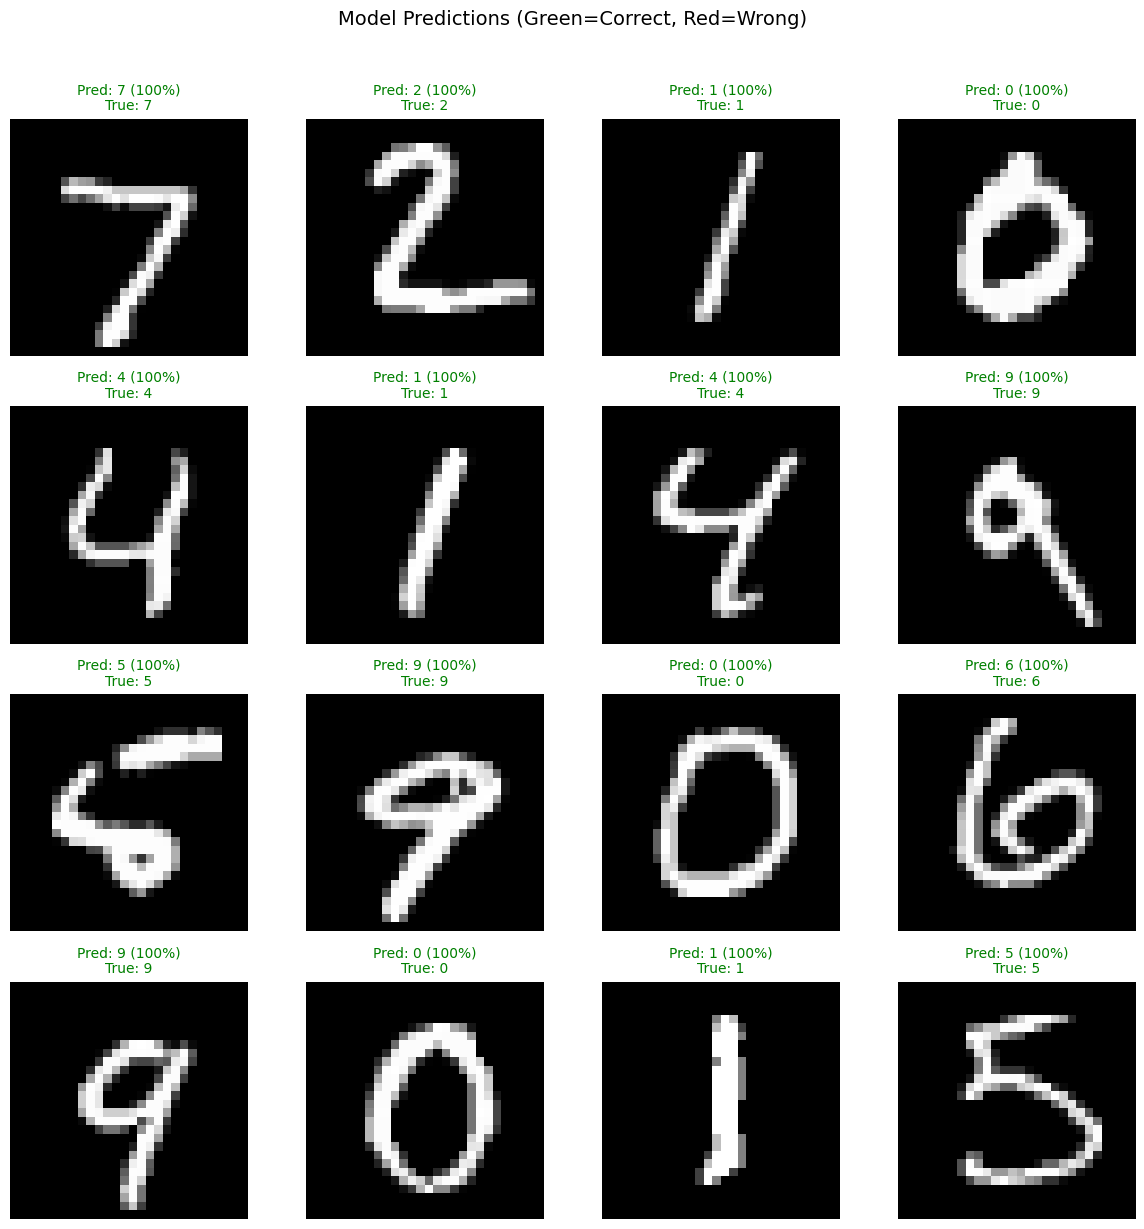

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

def visualize_predictions(model, test_loader, device, num_samples=16):
    model.eval()
    images, labels = [], []

    # Get one batch
    for imgs, lbls in test_loader:
        images, labels = imgs, lbls
        break

    images, labels = images.to(device), labels.to(device)

    with torch.no_grad():
        outputs = model(images[:num_samples])
        probs = F.softmax(outputs, dim=1)
        preds = probs.argmax(dim=1)

    # Plot
    fig, axes = plt.subplots(4, 4, figsize=(12, 12))
    for i, ax in enumerate(axes.flat):
        img = images[i].cpu().squeeze().numpy()
        pred = preds[i].item()
        true = labels[i].item()
        conf = probs[i][pred].item()

        ax.imshow(img, cmap='gray')
        color = 'green' if pred == true else 'red'
        ax.set_title(f"Pred: {pred} ({conf:.0%})\nTrue: {true}",
                     color=color, fontsize=10)
        ax.axis('off')

    plt.suptitle("Model Predictions (Green=Correct, Red=Wrong)",
                 fontsize=14, y=1.02)
    plt.tight_layout()
    plt.savefig('predictions.png', dpi=150, bbox_inches='tight')
    plt.show()

# Run
visualize_predictions(advanced_cnn, test_loader, device)